# repair2 데이터 분석

- 원본 데이터: 같은 폴더의 `repair2.csv`
- 목표: 수리 요청의 처리 구조를 이해하고 중단·반복·병목 후보를 검증해 개선안을 제안합니다.
- 진행: 전처리 → 기본 분석 → 시작·종료 후보 → 날짜 검증 및 복원 → 실제 흐름·분기 → 도달률·중단 후보 → 소요 시간·병목 → 담당자·수리 속성 → 개선안

## 목차

| 단계 | 주제 | 단계별 기록 |
| --- | --- | --- |
| 1~6 | 원본 탐색·전처리 | 기존 처리 기록 |
| 7 | 기본 분석 | 핵심 발견 / 다음에 확인할 것 |
| 8 | 프로세스 시작·종료 후보 파악 | 업무 구성에 따른 후보 / 판단 근거 |
| 9 | 날짜 검증 및 복원 | 날짜 처리 기준 / 사용 가능 범위 |
| 10 | 프로세스 흐름 및 분기 분석 | 실제 경로 / 연결 검증 / 프로세스 맵 |
| 11 | 단계별 도달률 및 중단 후보 분석 | 경로별 진입 대상 / 도달률 / 종료·중단 구분 |
| 12 | 소요 시간 및 병목 분석 | 처리·대기 시간 / 병목 근거 |
| 13 | 담당자별 업무 분석 | 업무 배분 / 동일 업무 내 시간 차이 |
| 14 | 수리 속성과 소요 시간의 관계 분석 | 속성별 차이 / 관련 요인 후보 |
| 15 | 분석 결과 종합 및 개선 방안 | 문제 → 근거 → 개선안 → 검증 지표 |
| 16 | 최종 PPT 구성 | 슬라이드 핵심 메시지 / 근거 자료 |

**진행 기준:** 업무 구성으로 후보를 파악한 뒤 날짜를 검증합니다. 검증한 시각으로 실제 경로를 확인하고, 경로별 도달률과 소요 시간을 분석합니다. 이후 담당자·요청 특성과의 관계를 살펴보고 개선안으로 연결합니다.

**PPT 권장 흐름:** 문제와 데이터 → 전처리·날짜 처리 기준 → 실제 경로·분기 → 도달률·중단 후보 → 소요 시간·병목 → 담당자·수리 속성 → 개선안·검증 지표 → 한계.


----

## 1. 데이터 불러오기 및 결측값 확인

원본 데이터를 불러오고 행·열 수, 칼럼별 자료형과 결측값 확인
원본을 유지하기 위해 DataFrame을 복사한 뒤 작업

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv('repair2.csv', encoding='utf-8-sig')

df = raw.copy(deep=True) #원본을 유지하기 위해 copy()를 사용하여 DataFrame을 복사합니다.

df.head()

,caseID,taskID,originator,eventtype,contact,RepairType,objectKey,RepairInternally,EstimatedRepairTime,RepairCode,RepairOK,date,time
0,419,InformClientSurvey,System,complete,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-06,11:51
1,561,ArrangeSurvey,Monica,complete,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-07,13:48
2,902,ReadyInformClient,System,complete,NaN,NaN,NaN,NaN,NaN,NaN,True,2020-01-08,16:20
3,18,Survey,Edd,start,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020-01-09,6:55
4,852,Survey,Edd,complete,NaN,NaN,NaN,True,240.0,1.0,NaN,2020-01-10,11:33


In [4]:
print(df.info())
print("===="*20)

print(f"Shape of the DataFrame: {df.shape}")
print("===="*20)

# 각 컬럼의 결측값 확인
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13262 entries, 0 to 13261
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   caseID               13262 non-null  int64  
 1   taskID               13260 non-null  object 
 2   originator           13260 non-null  object 
 3   eventtype            13257 non-null  object 
 4   contact              1000 non-null   object 
 5   RepairType           927 non-null    object 
 6   objectKey            927 non-null    float64
 7   RepairInternally     927 non-null    object 
 8   EstimatedRepairTime  927 non-null    float64
 9   RepairCode           927 non-null    float64
 10  RepairOK             1854 non-null   object 
 11  date                 13249 non-null  object 
 12  time                 13249 non-null  object 
dtypes: float64(3), int64(1), object(9)
memory usage: 1.3+ MB
None
Shape of the DataFrame: (13262, 13)


caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
dtype: int64

**분석 결과 기록**

- date와 time 칼럼의 type 수정 필요
- 원본을 유지하기 위해 copy()를 사용하여 DataFrame을 복사


## 2. 데이터 타입 변환

EstimatedRepairTime의 숫자형 확인 및 RepairInternally·RepairOK의 boolean 변환
변환 전후 자료형과 결측값 수를 비교하고 기존 값이 유지되는지 확인

In [5]:
df['EstimatedRepairTime'] = pd.to_numeric(
    df['EstimatedRepairTime'], errors='coerce')
print("===="*20)

# 실제 어떤 값이 있는지 확인
print(df['RepairInternally'].value_counts(dropna=False))
print(df['RepairOK'].value_counts(dropna=False))
print("===="*20)

# # 문자 'TRUE'/'FALSE'를 boolean 타입으로 변환
df['RepairInternally'] = df['RepairInternally'].astype('boolean')
df['RepairOK'] = df['RepairOK'].astype('boolean')

# print(df.dtypes)
df.isna().sum()

RepairInternally
NaN      12335
True       868
False       59
Name: count, dtype: int64
RepairOK
NaN     11408
True     1854
Name: count, dtype: int64


caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
dtype: int64

**분석 결과 기록**

- 다수의 결측치를 가진 칼럼이 존재
- 결측치가 필요에 의한 결측치인지 무의미한 결측치인지 확인 필요


## 3. datetime 변환

date와 time을 결합해 timestamp 생성
원본 칼럼은 유지하고 원본 시각 누락과 형식 변환 실패를 구분

In [6]:
# 날짜와 시간을 합쳐 datetime으로 변환
df['timestamp'] = pd.to_datetime( df['date'] + ' ' + df['time'], format='%Y-%m-%d %H:%M', errors='coerce')

# 결측값 확인
missing_source = df['date'].isna() | df['time'].isna()
# 결측값이 있는 경우와 형식 변환에 실패한 경우를 확인
parse_failure = ~missing_source & df['timestamp'].isna()

print('원본 시각 누락:', missing_source.sum())
print('type 변환 실패:', parse_failure.sum())

# 결측값이 있는 행 출력
print(df.loc[df['timestamp'].isna(), ['caseID', 'date', 'time']])

원본 시각 누락: 13
type 변환 실패: 0
       caseID date time
860       992  NaN  NaN
1078      113  NaN  NaN
3135      129  NaN  NaN
4526      100  NaN  NaN
5771      119  NaN  NaN
6225      123  NaN  NaN
6612      180  NaN  NaN
8144      146  NaN  NaN
9715      116  NaN  NaN
10235     154  NaN  NaN
10369     101  NaN  NaN
10406     106  NaN  NaN
10526     154  NaN  NaN


**분석 결과 기록**

- 전체 13,262행 중 날짜·시간 결측값이 13행에서 확인됨. 총 12개 케이스에 해당함
- 결측값은 start 4건, complete 8건, eventtype 미기록 1건으로 구성됨
- 원본 결측값 외에 datetime 형식 변환에 실패한 데이터는 없음
- 현재 단계에서는 결측값을 삭제하거나 대체하지 않고 유지함
- 시간 정보가 없더라도 업무 수행 기록은 프로세스 흐름 분석에 활용할 수 있기 때문임
- 소요 시간 분석 시 결측값이 계산 결과에 미치는 영향을 확인한 후 제외 여부를 결정할 예정임
- 결측값이 발생한 업무와 케이스의 특성 확인
- 업무별 start,complete 이벤트의 정상적인 연결 여부 확인
- 결측값 및 날짜 이상값이 소요 시간과 병목 분석에 미치는 영향 검토


## 4. 변환 결과 점검

1. 데이터 타입을 변환하는 과정에서 기존 값이 의도치 않게 결측값으로 바뀌지 않았는지 검증
2. 연도 분포를 확인하고 날짜 이상값의 추가 검토 필요 여부 확인

In [7]:
print('처음 불러왔을 때의 결측값')
print(raw.isna().sum())
print("===="*20)

print('타입 변환 후의 결측값')
print(df.isna().sum())
print("===="*20)

print('변환된 날짜의 연도 분포')
df['timestamp'].dt.year.value_counts(dropna=False)

처음 불러왔을 때의 결측값
caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
dtype: int64
타입 변환 후의 결측값
caseID                     0
taskID                     2
originator                 2
eventtype                  5
contact                12262
RepairType             12335
objectKey              12335
RepairInternally       12335
EstimatedRepairTime    12335
RepairCode             12335
RepairOK               11408
date                      13
time                      13
timestamp                 13
dtype: int64
변환된 날짜의 연도 분포


timestamp
1970.0    12383
2021.0      365
2020.0      361
2022.0      134
NaN          13
1905.0        6
Name: count, dtype: int64

**분석 결과 기록**

- 데이터 타입 변환 전후 결측값 개수를 비교한 결과 `date`와 `time`의 결측값은 각각 13건이며 생성된 `timestamp`의 결측값도 13건으로 확인됨
- 연도별 분포에서 1970년 데이터가 12,383건(약 93.4%)으로 대부분을 차지함
- 1905년 데이터도 6건 확인되어 날짜의 정합성 검토가 필요함
- 날짜 변환 후 결측값이 추가로 발생했는지 확인하고 원본 결측값과 비교함
- 1970년과 1905년 데이터는 오류 여부가 확인되지 않았으므로 현재 단계에서는 수정하거나 제거하지 않음
- 1970년과 1905년 날짜가 기록된 원인 확인
- 날짜 이상값이 케이스별 소요 시간 계산에 미치는 영향 검토


## 5. 결측값 검토 및 처리 기준

1. 결측값의 발생 현황을 바탕으로 분석 목적에 따른 처리 기준을 결정한다.
2. 현재는 원본 데이터를 유지하고 실제 분석 시 필요한 경우 처리 여부를 재검토한다.

In [8]:
# 시간 정보가 없는 이벤트 수 확인
print('timestamp 결측:', df['timestamp'].isna().sum())

timestamp 결측: 13


**분석 결과 기록**

- 전체 13,262행 중 `timestamp`가 존재하는 데이터는 13,249행(약 99.9%)이며 결측 데이터는 13행(약 0.1%)으로 확인됨.
- `contact`, `RepairOK`, `RepairInternally`, `EstimatedRepairTime` 등 시간 외 칼럼의 결측값은 현재 단계에서 삭제하거나 대체하지 않고 유지함.
- 값과 기록 여부가 업무 특성이나 소요 시간과 관련될 가능성이 있어, 결측을 일괄 제거하거나 0·False로 채우지 않음.
- `timestamp` 유무에 따라 `time_ready`와 `time_hold`로 데이터를 분리함.
- 시간 정보가 없는 13행은 소요 시간 계산에 활용하기 어려우므로 별도로 보류함.
- 원본 데이터는 삭제하지 않고 유지하며 시간 분석에 사용할 데이터는 추가 검증 후 확정하기로 함.
- `time_ready`에 포함된 데이터의 시간 순서 및 정합성 검증
- `time_hold`에 포함된 13행이 소요 시간 분석에 미치는 영향 확인
- 주요 칼럼이 특정 업무 이벤트에만 기록되는지, 케이스 전체에서 누락된 것인지 구분
- 날짜와 시작·완료 연결을 검증한 뒤 값·기록 여부에 따른 작업시간 및 케이스 소요 시간 차이 비교
- 수리 종류와 프로세스 경로 차이를 함께 확인하고, 관찰된 차이만으로 원인이라고 단정하지 않음


----

## 7. 기본 분석 — EDA 이전 작업

**A. 전체와 기록 단위 이해 → B. 케이스별 업무 구성 → C. 요청 속성 정리**

    - 시간 데이터가 불완전하더라도 진행할 수 있는 집계부터 시작.
    - 전체 빈도는 `df`로 확인하고 이벤트 수와 케이스 수를 구분

### A. 전체와 기록 단위 이해


#### 7-1. 전체 규모
데이터에 요청·이벤트·업무·담당자가 각각 얼마나 있는가?

In [9]:
# 전체 데이터 규모 확인
print('전체 이벤트 수:', len(df))
print('전체 수리 요청 수:', df['caseID'].nunique())
print('전체 업무 종류 수:', df['taskID'].nunique())
print('전체 담당자 수:', df['originator'].nunique())

전체 이벤트 수: 13262
전체 수리 요청 수: 1000
전체 업무 종류 수: 13
전체 담당자 수: 16


**분석 결과 기록**
- 전체 1,000건의 수리 요청에서 13,262개의 이벤트가 발생했으며 요청당 평균 약 13.26개의 이벤트가 기록됨.
- 하나의 수리 요청이 여러 업무 이벤트로 구성되는 데이터 구조임을 확인함.

#### 7-2. 업무별 이벤트 빈도
어떤 업무가 많이 기록됐으며 이벤트 수를 업무 수행 횟수로 볼 수 있는가?

In [10]:
# 업무별 이벤트 발생 횟수
task_counts = df['taskID'].value_counts(dropna=False)

print(task_counts.to_string())

taskID
ArrangeSurvey             1854
Survey                    1854
MakeTicket                1854
InternRepair              1094
FirstContact               999
ReadyInformClient          927
RepairReady                927
TicketReady                927
SendTicketToFinAdmin       927
InformClientSurvey         926
ImmediateRepair            766
ExternRepair               132
InformClientWrongPlace      73
NaN                          2


**분석 결과 기록**
  - `ArrangeSurvey`, `Survey`, `MakeTicket`은 각각 1,854건으로 동일한 이벤트 수가 확인됨
  - `ReadyInformClient`, `RepairReady`, `TicketReady` 등 일부 업무에서도 927건으로 동일한 이벤트 수가 나타남
  - 업무별 이벤트 수에 일정한 패턴이 존재하며 일부 업무가 공통적으로 수행되거나 연결되어 있을 가능성이 있음

#### 7-3. 시작·완료 기록 구조
각 업무는 `start`와 `complete` 중 무엇을 기록하는가?

In [11]:
# 전체 이벤트 유형별 발생 횟수
# 결측치를 하나의 그룹으로 측정
print(df['eventtype'].value_counts(dropna=False).to_string())

# 업무별 시작·완료 이벤트 분포
print(pd.crosstab(
    df['taskID'],
    df['eventtype'],
    dropna=False
).to_string())

eventtype
complete    9416
start       3841
NaN            5
eventtype               complete  start  NaN
taskID                                      
ArrangeSurvey                927    926    1
ExternRepair                   0    132    0
FirstContact                 999      0    0
ImmediateRepair              383    382    1
InformClientSurvey           925      0    1
InformClientWrongPlace        73      0    0
InternRepair                 547    547    0
MakeTicket                   927    927    0
ReadyInformClient            927      0    0
RepairReady                  927      0    0
SendTicketToFinAdmin         927      0    0
Survey                       926    927    1
TicketReady                  926      0    1
NaN                            2      0    0


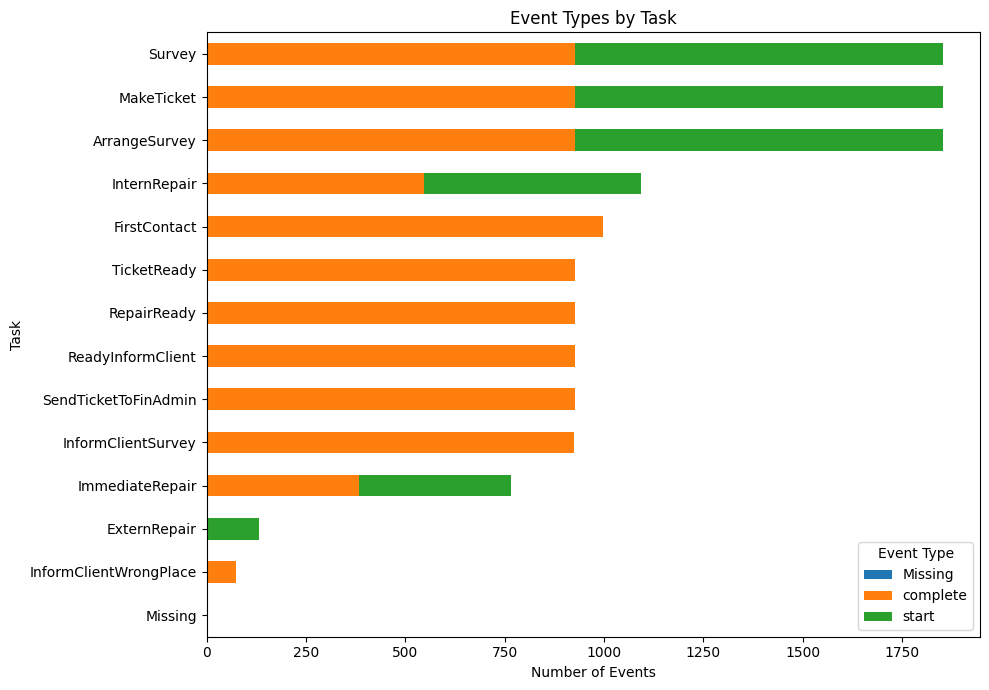

In [12]:
# 업무별 이벤트 유형 집계
event_counts = pd.crosstab(
    df['taskID'].fillna('Missing'),
    df['eventtype'].fillna('Missing')
)

# 이벤트 수가 많은 업무부터 정렬
event_counts = event_counts.loc[
    event_counts.sum(axis=1).sort_values().index
]

# 시각화
event_counts.plot.barh(stacked=True, figsize=(10, 7))

plt.xlabel('Number of Events')
plt.ylabel('Task')
plt.title('Event Types by Task')
plt.legend(title='Event Type')
plt.tight_layout()
plt.show()

**분석 결과 기록**
- 업무에 따라 시작과 완료가 모두 기록되거나 한쪽 이벤트만 기록되는 차이가 확인됨
- ExternRepair는 시작 이벤트만 132건 기록되어 있으며 완료 이벤트는 확인되지 않음
- eventtype 결측값이 5건 존재함.

### B. 케이스별 업무 구성


#### 7-4. 케이스별 이벤트 수
요청마다 기록 수는 얼마나 다르고 그 차이는 어떤 의미인가?

In [13]:
# 케이스별 이벤트 수 집계
case_counts = df['caseID'].value_counts()

# 이벤트 수의 분포 확인
print('최소:', case_counts.min())
print('평균:', case_counts.mean())
print('중앙값:', case_counts.median())
print('최대:', case_counts.max())
print('===='*20)

# 이벤트 수가 많은 상위 10개 케이스
print(case_counts.sort_values(ascending=False).head(10))

최소: 2
평균: 13.262
중앙값: 14.0
최대: 18
caseID
512    18
865    18
456    17
775    17
613    17
41     17
653    17
776    17
425    16
904    16
Name: count, dtype: int64


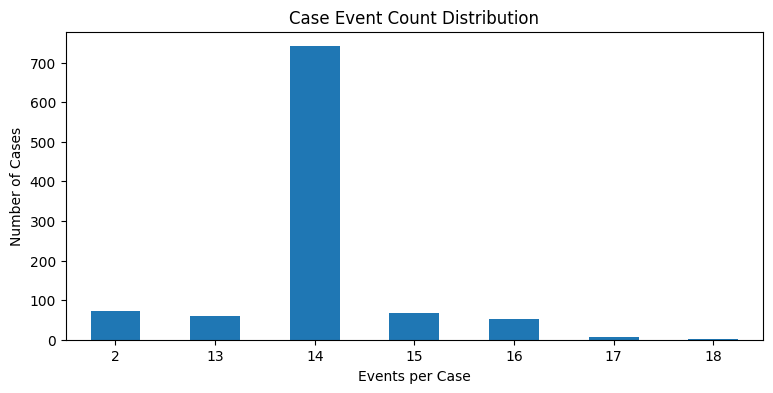

In [14]:

# 케이스별 이벤트 수
case_counts = df['caseID'].value_counts()

# 이벤트 수별 케이스 분포
event_dist = case_counts.value_counts().sort_index()

event_dist.plot.bar(figsize=(9, 4))
plt.xlabel('Events per Case')
plt.ylabel('Number of Cases')
plt.title('Case Event Count Distribution')
plt.xticks(rotation=0)  # X축 숫자를 가로로 표시
plt.show()

**분석 결과 기록**

- 케이스별 이벤트 수의 평균은 13.26건이지만 중앙값과 최빈값은 모두 14건으로 나타남
- 전체 케이스의 74.1%가 14개 이벤트에 집중되어 있으며 이벤트 수가 2개인 케이스가 평균에 영향을 미치므로 일반적인 이벤트 수를 설명하는 지표로 중앙값을 선택함
- 단 이벤트 수가 2개이거나 17~18개인 케이스가 반드시 통계적 이상치인 것은 아님. 따라서 실제 업무 구성의 차이인지 확인 필요

#### 7-5. 케이스별 업무 종류 수
이벤트가 많은 케이스는 실제로 업무 종류도 많은가?


In [15]:
# 케이스별 업무 종류 수
case_task_kinds = df.groupby('caseID')['taskID'].nunique()

# 업무 종류 수의 분포
print(case_task_kinds.value_counts().sort_index())

taskID
2      73
9       1
10    836
11     85
12      5
Name: count, dtype: int64


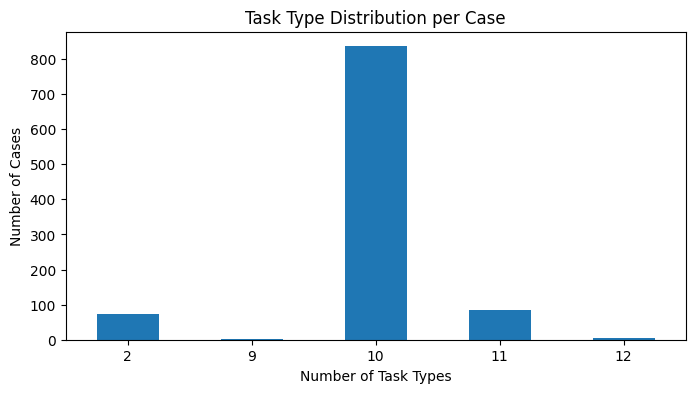

In [16]:
# 케이스별 업무 종류 수
case_task_kinds = df.groupby('caseID')['taskID'].nunique()

# 업무 종류 수별 케이스 분포
task_dist = case_task_kinds.value_counts().sort_index()

# 시각화
task_dist.plot.bar(figsize=(8, 4))

plt.xlabel('Number of Task Types')
plt.ylabel('Number of Cases')
plt.title('Task Type Distribution per Case')
plt.xticks(rotation=0)
plt.show()

**분석 결과 기록**

- 앞선 분석에서는 케이스별 이벤트 수를 확인했으나 하나의 업무에서 start와 complete가 각각 기록될 수 있어 이벤트 수와 실제 업무 종류 수가 다르다는 점을 확인함
- 이에 케이스별 중복되지 않는 taskID의 개수를 집계하여 업무 종류 수의 분포를 분석함
- 분석 결과 전체 1,000개 케이스 중 836건(83.6%)이 10종류의 업무를 포함하며 가장 일반적인 구성 규모로 나타남
- 다만 업무 종류 수가 같더라도 실제 업무 조합은 다를 수 있으므로 다음 분석에서 케이스별 업무 구성을 비교할 예정임


#### 7-6. 업무 조합과 대표 사례
같은 종류 수를 가진 케이스도 업무 조합이 다른가?

In [17]:
# 케이스별 중복·결측을 제외한 업무 조합 생성
case_patterns = df.groupby('caseID')['taskID'].agg(lambda x: tuple(sorted(x.dropna().unique()))
)
# 전체 업무 조합의 종류 수 확인 (중복 제거)
print('전체 업무 조합 수:', case_patterns.nunique())
print('====='*20)

# 서로 다른 10가지 업무 조합과 각 조합에 해당하는 케이스 수를 출력
print('\n' + case_patterns.value_counts().to_string())

전체 업무 조합 수: 10

taskID
(ArrangeSurvey, FirstContact, InformClientSurvey, InternRepair, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                                   454
(ArrangeSurvey, FirstContact, ImmediateRepair, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                                322
(FirstContact, InformClientWrongPlace)                                                                                                                                                    73
(ArrangeSurvey, ExternRepair, FirstContact, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                                    59
(ArrangeSurvey, ExternRepair, FirstContact, ImmediateRepair, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)                   37
(ArrangeSurvey, ExternRepair, Fi

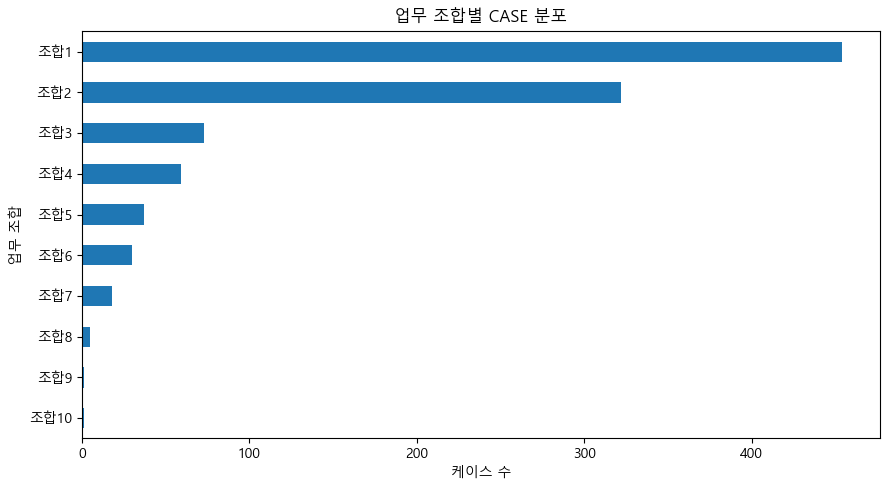

                                                                                                                                                                         task_pattern  case_count pattern_id
                               (ArrangeSurvey, FirstContact, InformClientSurvey, InternRepair, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)         454        조합1
                            (ArrangeSurvey, FirstContact, ImmediateRepair, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady)         322        조합2
                                                                                                                                               (FirstContact, InformClientWrongPlace)          73        조합3
                               (ArrangeSurvey, ExternRepair, FirstContact, InformClientSurvey, MakeTicket, ReadyInformClient, RepairReady, SendTicketToFinAdmin, Survey, TicketReady

In [18]:
# 한글 폰트 설정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 업무 조합별 케이스 수
pattern_counts = case_patterns.value_counts()

# 업무 조합에 번호 부여
pattern_df = pattern_counts.reset_index()
pattern_df.columns = ['task_pattern', 'case_count']
pattern_df['pattern_id'] = [
    f'조합{i+1}' for i in range(len(pattern_df))
]

# 시각화
pattern_df.plot.barh(
    x='pattern_id',
    y='case_count',
    figsize=(9, 5),
    legend=False
)

plt.gca().invert_yaxis()
plt.xlabel('케이스 수')
plt.ylabel('업무 조합')
plt.title('업무 조합별 CASE 분포')
plt.tight_layout()
plt.show()

# 조합별 실제 업무 구성 확인
print(pattern_df.to_string(index=False))

**분석 결과 기록**
- 전체 1,000개 케이스에서 총 10가지 업무 조합이 확인됨
- InternRepair를 포함한 조합이 454건(45.4%)으로 가장 많았으며 ImmediateRepair를 포함한 조합이 322건(32.2%)으로 그다음으로 많았음
- FirstContact와 InformClientWrongPlace만 포함된 케이스도 73건(7.3%) 확인되어 별도의 처리 경로가 존재할 가능성이 있음
- 다만 업무 조합은 업무의 포함 여부만 나타내므로 실제 수행 순서와 반복 여부는 확인할 수 없음


### C. 요청 속성 정리


#### 7-7. 접수 채널
어떤 채널로 접수됐으며 접수 채널별로 값이 일관되는가?


In [19]:
# 케이스별 접수 채널 추출
case_contact = df.groupby('caseID')['contact'].first()

# 접수 채널별 케이스 수
print(case_contact.value_counts(dropna=False))

# 접수 채널의 결측 및 중복 기록 확인
print('채널 미기록 케이스:', case_contact.isna().sum())
print('복수 채널 기록 케이스:',
      (df.groupby('caseID')['contact'].nunique() > 1).sum())

contact
Phone       270
Web         265
Personal    240
Letter      225
Name: count, dtype: int64
채널 미기록 케이스: 0
복수 채널 기록 케이스: 0


**분석 결과 기록**

- Phone(27.0%)과 Web(26.5%)의 접수 비중이 가장 높았으나 Personal(24.0%)과 Letter(22.5%)를 포함한 전체 채널의 요청 비중은 비교적 고르게 분포함
- 접수 채널이 누락되거나 하나의 케이스에 복수 채널이 기록된 사례는 확인되지 않음.

#### 7-8. 수리 속성
- 수리 방식·내부 수리 여부 등의 요청별 분포는 어떠한가?
- `RepairType`, `RepairInternally`, `RepairCode`, `EstimatedRepairTime`과 같이 결측치가 많았던 칼럼들을 기준으로 확인

In [20]:
# 수리 속성 컬럼 정의
repair_cols = ['RepairType', 'RepairInternally', 'RepairCode']

# 각 컬럼에서 첫 번째 결측이 아닌 값 출력
case_repair = df.groupby('caseID')[repair_cols].first()

# 수리 속성별 요청 수 확인
for col in repair_cols:
    print(f'\n=== {col} ===')
    print(case_repair[col].value_counts(dropna=False))

print("===="*20)

# 케이스 내 서로 다른 속성값 존재 여부 확인
for col in repair_cols:
    conflicts = (df.groupby('caseID')[col].nunique() > 1).sum()
    print(f'{col} 값 충돌 케이스: {conflicts}')


=== RepairType ===
RepairType
P       439
E       370
B       118
None     73
Name: count, dtype: int64

=== RepairInternally ===
RepairInternally
True     868
<NA>      73
False     59
Name: count, dtype: Int64

=== RepairCode ===
RepairCode
1.0    550
2.0    224
3.0     94
NaN     73
4.0     59
Name: count, dtype: int64
RepairType 값 충돌 케이스: 0
RepairInternally 값 충돌 케이스: 0
RepairCode 값 충돌 케이스: 0


**분석 결과 기록**

- 이벤트 단위에서 약 93%였던 수리 속성 컬럼의 결측률이 케이스 단위에서는 7.3%로 확인됨
- RepairType은 P(43.9%)와 E(37.0%)가 대부분을 차지했으며 RepairInternally는 내부 수리(True)가 86.8%로 가장 높게 나타남
- RepairCode는 1번 유형이 55.0%로 가장 많았으며 세 컬럼 모두 동일 케이스 내 값 충돌은 확인되지 않음
- 세 컬럼에서 공통적으로 73개 케이스의 정보가 누락됨.


----

## 8. 프로세스 시작·종료 후보 파악

**분석 목적:** 시간 정보를 사용하기 전에 업무 구성만으로 시작과 종료에 해당할 가능성이 있는 업무를 확인한다.

**앞 단계와의 연결·다음 작업:** 7단계에서 확인한 업무 조합을 바탕으로 시작·종료 후보를 정리한다. 실제 순서를 확인하려면 날짜를 믿을 수 있어야 하므로, 다음에는 날짜 검증을 진행한다.

**산출물:** 시작·종료 업무 후보와 업무 구성에 따른 종료 유형 후보

> **주의:** 아직 시간순으로 확인하지 않았으므로 실제 첫 번째·마지막 업무라고 확정하지 않는다. 업무 이름만으로 정상 완료를 확정하지 않는다.


#### 8-1. 시작 업무 후보 확인

**확인할 내용**

- FirstContact 등 접수 관련 업무의 케이스별 기록 여부 확인
- 최초 접수 업무 기록 없이 남아 있는 케이스가 있는지 확인

In [21]:
from IPython.display import display

# 케이스별 업무 존재 여부
case_tasks = pd.crosstab(df['caseID'], df['taskID']).gt(0)

# 시작 및 종료 관련 업무별 케이스 수
check_tasks = [
    'FirstContact',
    'MakeTicket',
    'InformClientWrongPlace',
    'RepairReady',
    'TicketReady',
    'ReadyInformClient'
]

task_summary = case_tasks[check_tasks].sum().to_frame('케이스 수')
display(task_summary)

# FirstContact 미기록 케이스
missing_contact = case_tasks.index[~case_tasks['FirstContact']]
display(pd.DataFrame({'FirstContact 미기록 caseID': missing_contact}))

# 종료 경로 조합
end_paths = pd.crosstab(
    case_tasks['InformClientWrongPlace'],
    case_tasks['TicketReady']
)

display(end_paths)

,케이스 수
taskID,
FirstContact,999
MakeTicket,927
InformClientWrongPlace,73
RepairReady,927
TicketReady,927
ReadyInformClient,927


,FirstContact 미기록 caseID
0,245


TicketReady,False,True
InformClientWrongPlace,,
False,0,927
True,73,0


**분석 결과 기록**

- 전체 1,000개 케이스 중 999개에서 FirstContact가 기록되었으며 1개 케이스(caseID 245)에서는 기록되지 않음
- TicketReady는 927개 케이스(92.7%)에서 확인되었고 InformClientWrongPlace는 73개 케이스(7.3%)에서 확인됨
- 두 업무가 동일한 케이스에서 함께 나타나거나 모두 누락된 사례는 없어 서로 다른 두 가지 처리 경로가 존재할 것으로 예상


#### 8-2. 종료 업무 후보 확인

- TicketReady, ReadyInformClient, InformClientWrongPlace 등 종료 관련 업무 확인
- 가설: 정상적인 프로세스 외에 별도의 프로세스가 존재할 것이다.

In [22]:
# 케이스별 프로세스 유형 분류
case_paths = case_tasks['InformClientWrongPlace'].map({
    True: '예외 처리 경로',
    False: '일반 프로세스'
}).rename('프로세스 유형')

# 프로세스 유형별 업무 구성 비교
path_tasks = case_tasks.groupby(case_paths).sum().T
display(path_tasks)

# 프로세스 유형별 수리 속성 기록 여부 비교
repair_missing = case_repair['RepairType'].isna()

display(pd.crosstab(
    case_paths,
    repair_missing
).rename(columns={False: '기록', True: '미기록'}))

프로세스 유형,예외 처리 경로,일반 프로세스
taskID,,
ArrangeSurvey,0,927
ExternRepair,0,132
FirstContact,73,926
ImmediateRepair,0,383
InformClientSurvey,0,926
InformClientWrongPlace,73,0
InternRepair,0,508
MakeTicket,0,927
ReadyInformClient,0,927


RepairType,기록,미기록
프로세스 유형,,
예외 처리 경로,0,73
일반 프로세스,927,0


**분석 결과 기록**

- 전체 1,000개 케이스는 일반 프로세스 927건(92.7%)과 예외 처리 경로 73건(7.3%)으로 구분됨
- 예외 처리 경로는 FirstContact와 InformClientWrongPlace만 기록되었으며 일반 프로세스의 수리 관련 업무는 나타나지 않음
- RepairType이 미기록된 73개 케이스는 모두 예외 처리 경로에 해당
- 일반 프로세스에서는 InternRepair 508건, ImmediateRepair 383건, ExternRepair 132건이 확인되었으며 한 케이스에 여러 수리 업무가 포함될 가능성이 있음

----

## 9. 날짜 검증 및 복원
시간순 업무 분석과 처리 시간 계산에 사용할 날짜의 신뢰성을 확보


#### 9-1. 날짜 이상 패턴 확인
- 1905년, 1970년, 2020~2022년 데이터 분포 확인
- 이상 날짜가 특정 이벤트나 케이스에 집중되는지 확인

In [23]:
import matplotlib.pyplot as plt

# 연도별 이벤트 분포
year_counts = (
    df['timestamp'].dt.year
    .value_counts(dropna=False)
    .sort_index()
)

display(year_counts.to_frame('이벤트 수'))

# 여러 연도가 기록된 케이스 확인
# 임시 칼럼을 추가하여 복사본 생성
case_years = df.assign(
    year=df['timestamp'].dt.year
).groupby('caseID')['year'].nunique()

print('여러 연도가 기록된 케이스:', (case_years > 1).sum())

# 2020~2022년 이벤트 확인
date_anomaly = df[df['timestamp'].dt.year.between(2020, 2022)].copy()

print('2020~2022년 이벤트 수:', len(date_anomaly))
print('최소 행 인덱스:', date_anomaly.index.min())
print('최대 행 인덱스:', date_anomaly.index.max())

# 날짜가 하루씩 증가하는지 확인
date_only = date_anomaly['timestamp'].dt.normalize()

print(
    '날짜가 모두 하루 간격인가?:',
    date_only.diff().dropna().eq(pd.Timedelta(days=1)).all()
)

,이벤트 수
timestamp,
1905.0,6
1970.0,12383
2020.0,361
2021.0,365
2022.0,134
NaN,13


여러 연도가 기록된 케이스: 595
2020~2022년 이벤트 수: 860
최소 행 인덱스: 0
최대 행 인덱스: 859
날짜가 모두 하루 간격인가?: True


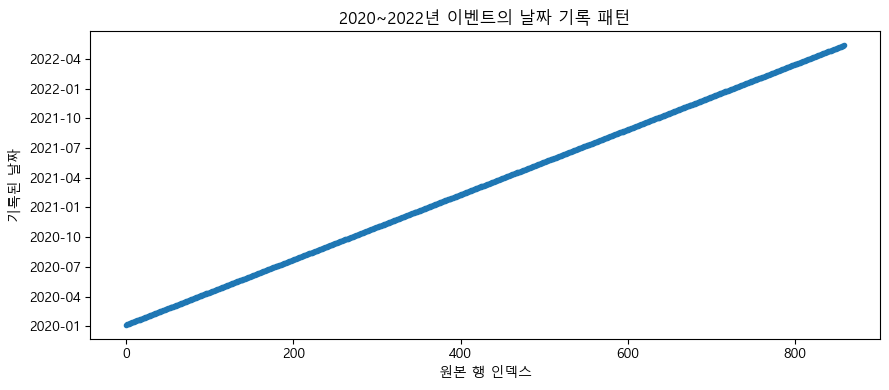

In [24]:
# 원본 행 순서별 날짜 변화
plt.figure(figsize=(9, 4))
plt.plot(date_anomaly.index, date_only, marker='.', linewidth=1)

plt.title('2020~2022년 이벤트의 날짜 기록 패턴')
plt.xlabel('원본 행 인덱스')
plt.ylabel('기록된 날짜')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 전체 13,262개 이벤트 중 1970년 기록이 12,383건으로 대부분을 차지하며 1905년 6건과 2020~2022년 860건도 확인됨
- 날짜 결측은 13건
- 2020~2022년 이벤트 860건은 원본 데이터의 0~859번 인덱스에 연속적으로 위치하며 날짜가 하루씩 증가하는 모습을 보임
- 동일한 케이스 내에서 서로 다른 연도가 기록된 사례가 595건 확인됨
- 특정 행 구간에서 규칙적인 날짜 증가가 확인되어 데이터 생성 또는 변환 과정에서 날짜가 변경되었을 가능성이 있음


#### 9-2. 동일 케이스 내 시간 정합성 점검
동일 케이스 내 업무의 시작,완료 시각을 비교하여 날짜 기록의 정합성을 검증
- 가설: 데이터 기록 또는 변환 과정에서 일부 이벤트의 날짜가 잘못 변경되어 동일 케이스 내 업무의 시작과 완료 시각에 비정상적인 차이가 발생했을 것이다.

In [25]:
# 시작·완료 이벤트만 선택
events = df[df['eventtype'].isin(['start', 'complete'])].copy()

# 케이스와 업무별 시작·완료 기록 수 확인
pair_counts = (
    events.groupby(['caseID', 'taskID', 'eventtype'])
    .size()
    .unstack(fill_value=0)
)

# 시작과 완료가 각각 1번씩 기록된 업무 선택
valid_keys = pair_counts[
    (pair_counts['start'] == 1) &
    (pair_counts['complete'] == 1)
].index

# 시작·완료 시각을 하나의 행으로 정리
paired_events = events.set_index(['caseID', 'taskID']).loc[valid_keys].reset_index()

pairs = paired_events.pivot(
    index=['caseID', 'taskID'],
    columns='eventtype',
    values='timestamp'
).reset_index()

# 시작·완료 시간 차이 계산
pairs['duration_hours'] = (
    pairs['complete'] - pairs['start']
).dt.total_seconds() / 3600

# 연도 불일치 여부
pairs['year_mismatch'] = (
    pairs['start'].notna() &
    pairs['complete'].notna() &
    (pairs['start'].dt.year != pairs['complete'].dt.year)
)

In [26]:
# 시간 정합성 요약
summary = pd.DataFrame({
    '건수': [
        len(pairs),
        pairs['duration_hours'].notna().sum(),
        (pairs['duration_hours'] < 0).sum(),
        pairs['year_mismatch'].sum()
    ]
}, index=[
    '시작·완료 1:1 업무',
    '시간 비교 가능',
    '완료가 시작보다 빠른 업무',
    '시작·완료 연도 불일치'
])

display(summary)

# 시간이 역전된 업무 사례
display(
    pairs[pairs['duration_hours'] < 0]
    .sort_values('duration_hours')
    .head(10)
)

,건수
시작·완료 1:1 업무,3631
시간 비교 가능,3627
완료가 시작보다 빠른 업무,226
시작·완료 연도 불일치,474


eventtype,caseID,taskID,complete,start,duration_hours,year_mismatch
940,260,ArrangeSurvey,1970-01-04 04:37:00,2022-05-01 04:34:00,-458639.950000,True
293,84,ArrangeSurvey,1970-01-07 12:50:00,2022-04-28 12:46:00,-458495.933333,True
2616,716,InternRepair,1970-01-12 05:44:00,2022-05-02 01:20:00,-458467.600000,True
1944,532,Survey,1970-01-03 05:34:00,2022-04-18 04:51:00,-458351.283333,True
2855,787,ArrangeSurvey,1970-01-03 14:16:00,2022-04-13 14:14:00,-458231.966667,True
1111,306,ArrangeSurvey,1970-01-02 15:11:00,2022-04-10 15:08:00,-458183.950000,True
3141,870,ArrangeSurvey,1970-01-07 14:50:00,2022-04-07 09:14:00,-457986.400000,True
345,97,InternRepair,1970-01-03 01:56:00,2022-03-31 22:16:00,-457940.333333,True
3260,902,ArrangeSurvey,1970-01-07 14:07:00,2022-04-02 12:24:00,-457870.283333,True
3516,971,MakeTicket,1970-01-03 17:25:00,2022-03-23 17:17:00,-457727.866667,True


In [27]:
# 시작 연도와 완료 연도 교차표
year_comparison = pd.crosstab(
    pairs['start'].dt.year,
    pairs['complete'].dt.year
)

display(year_comparison)

complete,1970.0,2020.0,2021.0,2022.0
start,,,,
1905.0,2,0,0,0
1970.0,3151,97,107,36
2020.0,93,0,3,2
2021.0,96,2,2,1
2022.0,32,3,0,0


**분석 결과 기록**

- 시작과 완료가 각각 1회 기록된 업무 3,631건 중 3,627건에서 시간 비교
- 226건(6.2%)에서 완료 시각이 시작 시각보다 빠른 시간 역전 현상이 확인됨
- 시작과 완료 연도가 다른 업무는 474건으로 확인됐으며 시간 역전 226건 모두 연도 불일치 사례에 해당
- 시간 역전 226건 중 221건은 2020~2022년에 시작되어 1970년에 완료된 것으로 기록됨


#### 9-3. 날짜 복원 가능성 검토
2020~2022년으로 기록된 이벤트에서 날짜만 변경되고 시각은 유지되었는지 확인

In [28]:
# 비교할 이벤트 추출
anomaly = df.loc[
    df['timestamp'].dt.year.between(2020, 2022),
    ['caseID', 'taskID', 'timestamp']
].copy()
anomaly['row_id'] = anomaly.index

normal = df.loc[
    df['timestamp'].dt.year.eq(1970),
    ['caseID', 'taskID', 'timestamp']
].copy()

# 시각(HH:MM)만 추출
anomaly['clock'] = anomaly['timestamp'].dt.strftime('%H:%M')
normal['clock'] = normal['timestamp'].dt.strftime('%H:%M')

# 1970년 비교 데이터의 컬럼명 변경
normal = normal.rename(columns={
    'taskID': 'ref_task',
    'timestamp': 'ref_timestamp'
})

# 동일 케이스에서 시각이 일치하는 이벤트 연결
matches = anomaly.merge(
    normal[['caseID', 'clock', 'ref_task', 'ref_timestamp']],
    on=['caseID', 'clock'],
    how='left'
)

# 이상 이벤트별 서로 다른 날짜 후보 개수
candidate_counts = matches.groupby('row_id')['ref_timestamp'].nunique()

summary = pd.DataFrame({
    '구분': ['일치 없음', '후보 1개', '후보 2개 이상'],
    '이벤트 수': [
        (candidate_counts == 0).sum(),
        (candidate_counts == 1).sum(),
        (candidate_counts > 1).sum()
    ]
})

display(summary)

# 날짜 복원 후보 사례 확인
display(matches.loc[
    matches['ref_timestamp'].notna(),
    ['row_id', 'caseID', 'taskID', 'timestamp', 'ref_task', 'ref_timestamp']
].head(10))

,구분,이벤트 수
0,일치 없음,224
1,후보 1개,634
2,후보 2개 이상,2


,row_id,caseID,taskID,timestamp,ref_task,ref_timestamp
0,0,419,InformClientSurvey,2020-01-06 11:51:00,ArrangeSurvey,1970-01-06 11:51:00
1,1,561,ArrangeSurvey,2020-01-07 13:48:00,InformClientSurvey,1970-01-04 13:48:00
5,5,450,TicketReady,2020-01-11 21:48:00,ReadyInformClient,1970-01-03 21:48:00
6,6,521,MakeTicket,2020-01-12 20:30:00,ArrangeSurvey,1970-01-02 20:30:00
8,8,604,MakeTicket,2020-01-14 18:37:00,FirstContact,1970-01-04 18:37:00
10,10,460,ArrangeSurvey,2020-01-16 08:37:00,InformClientSurvey,1970-01-03 08:37:00
11,11,870,TicketReady,2020-01-17 15:49:00,ReadyInformClient,1970-01-14 15:49:00
12,12,340,ArrangeSurvey,2020-01-18 23:18:00,MakeTicket,1970-01-07 23:18:00
14,14,325,RepairReady,2020-01-20 20:00:00,InternRepair,1970-01-06 20:00:00
17,17,447,FirstContact,2020-01-23 22:19:00,MakeTicket,1970-01-04 22:19:00


In [29]:
# 1905년 이벤트의 시간 확인
old_events = df[df['timestamp'].dt.year.eq(1905)]

display(old_events[
    ['caseID', 'taskID', 'eventtype', 'timestamp']
])

,caseID,taskID,eventtype,timestamp
1378,265,FirstContact,complete,1905-05-23
1880,180,MakeTicket,start,1905-05-23
5903,1,FirstContact,complete,1905-05-23
6333,318,MakeTicket,start,1905-05-23
8203,959,TicketReady,complete,1905-05-23
11301,992,SendTicketToFinAdmin,complete,1905-05-23


**분석 결과 기록**

- 2020~2022년 이벤트 860건 중 636건(74.0%)에서 동일 케이스의 1970년 이벤트와 시각이 일치하는 기록이 확인됨
- 이 중 634건은 일치하는 1970년 날짜,시각 후보가 1개였으며 2건은 후보가 2개 이상으로 나타남. 나머지 224건은 일치하는 기록이 없었음
- 일부 이벤트에서 날짜는 차이가 나지만 시각은 동일하게 기록되어 있어 날짜만 변경되고 시각은 유지되었을 가능성이 확인됨
- 1905년 이벤트 6건은 모두 1905-05-23 00:00으로 기록되어 있어 별도의 오류 의심


#### 9-4. 날짜 보정 규칙의 타당성 검증 및 처리 방향 결정
이상 패턴을 바탕으로 객관적인 규칙을 설정할 수 있는지 검토하고 이후 시간 분석에 사용할 데이터 처리 방향을 결정


##### 9-4-1. 날짜 보정 가능성 검토
2020~2022년의 날짜는 원본 행 순서에 따라 인위적으로 기록된 것일까?


In [30]:
# 2020~2022년 이벤트 추출
suspect = df[
    df['timestamp'].dt.year.between(2020, 2022)
].sort_index().copy()

# 첫 날짜를 기준으로 행 번호만큼 하루씩 증가한 날짜 생성
expected_dates = (
    suspect['timestamp'].dt.normalize().iloc[0]
    + pd.to_timedelta(suspect.index - suspect.index.min(), unit='D')
)

# 실제 날짜와 행 번호 기반 날짜 비교
matches_order = suspect['timestamp'].dt.normalize().eq(expected_dates)

print('검증 대상:', len(suspect))
print('행 번호 기반 날짜 규칙 일치:', matches_order.sum())
print('규칙 불일치:', (~matches_order).sum())

검증 대상: 860
행 번호 기반 날짜 규칙 일치: 860
규칙 불일치: 0


**분석 결과 기록**

- 하루씩 증가하는 날짜가 행 번호와 정확히 일치함을 확인
- 2020~2022년 날짜가 실제 업무 발생일보다 행 순서에 따라 생성된 값일 가능성이 높다


##### 9-4-2. 동일 시각을 활용한 보정 규칙 검증
동일한 시각의 이벤트가 발견됐을 때 서로 같은 업무인지 다른 업무인지 확인


In [31]:
# 동일 케이스·시각으로 연결된 이벤트
matched = matches[matches['ref_timestamp'].notna()].copy()

# 동일 시각 이벤트의 업무 일치 여부
matched['same_task'] = matched['taskID'].eq(matched['ref_task'])

summary = pd.DataFrame({
    '구분': ['시각 일치 이벤트', '동일 업무', '서로 다른 업무'],
    '이벤트 수': [
        matched['row_id'].nunique(),
        matched.loc[matched['same_task'], 'row_id'].nunique(),
        matched.loc[~matched['same_task'], 'row_id'].nunique()
    ]
})

display(summary)

# 실제 시각 일치 사례
display(matched[
    ['caseID', 'taskID', 'timestamp', 'ref_task', 'ref_timestamp']
].head(10))

,구분,이벤트 수
0,시각 일치 이벤트,636
1,동일 업무,0
2,서로 다른 업무,636


,caseID,taskID,timestamp,ref_task,ref_timestamp
0,419,InformClientSurvey,2020-01-06 11:51:00,ArrangeSurvey,1970-01-06 11:51:00
1,561,ArrangeSurvey,2020-01-07 13:48:00,InformClientSurvey,1970-01-04 13:48:00
5,450,TicketReady,2020-01-11 21:48:00,ReadyInformClient,1970-01-03 21:48:00
6,521,MakeTicket,2020-01-12 20:30:00,ArrangeSurvey,1970-01-02 20:30:00
8,604,MakeTicket,2020-01-14 18:37:00,FirstContact,1970-01-04 18:37:00
10,460,ArrangeSurvey,2020-01-16 08:37:00,InformClientSurvey,1970-01-03 08:37:00
11,870,TicketReady,2020-01-17 15:49:00,ReadyInformClient,1970-01-14 15:49:00
12,340,ArrangeSurvey,2020-01-18 23:18:00,MakeTicket,1970-01-07 23:18:00
14,325,RepairReady,2020-01-20 20:00:00,InternRepair,1970-01-06 20:00:00
17,447,FirstContact,2020-01-23 22:19:00,MakeTicket,1970-01-04 22:19:00


**분석 결과 기록**

- 동일 시각으로 연결된 636건 모두 서로 다른 업무의 기록으로 확인됨
- 업무 간 전환 시각은 유지되었지만 날짜가 잘못 기록되었을 가능성이 있음
- 즉 임의로 날짜를 수정하는 것은 위험함


##### 9-4-3. 날짜 처리 방향 결정


In [32]:
# 날짜 처리 방향: 원본 보존, 임의 보정 제외
df['date_status'] = '검증 필요'

df.loc[df['timestamp'].dt.year.eq(1970), 'date_status'] = '1970년 기록'
df.loc[df['timestamp'].dt.year.between(2020, 2022), 'date_status'] = '날짜 이상 의심'
df.loc[df['timestamp'].dt.year.eq(1905), 'date_status'] = '날짜 이상 의심'
df.loc[df['timestamp'].isna(), 'date_status'] = '날짜 결측'

display(df['date_status'].value_counts().to_frame('이벤트 수'))

,이벤트 수
date_status,
1970년 기록,12383
날짜 이상 의심,866
날짜 결측,13


**분석 결과 기록**
- 날짜 원본은 유지하고 시간 분석에 사용할 수 있는 이벤트와 케이스의 범위를 별도로 결정


#### 9-5. 시간 분석 대상 확정
날짜 이상이 있는 상황에서 전체 프로세스 분석과 처리 시간 분석에 각각 어떤 데이터를 사용할 수 있을까?
- 1970년 기록을 정상 날짜로 확정한 것은 아니다. 단지 다른 연도가 섞이지 않은 상대적으로 일관된 기록을 우선 분석 대상으로 사용하는 보수적인 기준

In [33]:
# 업무별 시간 분석 대상
pair_time_ok = (
    pairs['start'].dt.year.eq(1970) &
    pairs['complete'].dt.year.eq(1970) &
    (pairs['complete'] >= pairs['start'])
)

time_pairs = pairs[pair_time_ok].copy()

# 케이스별 시간 분석 대상
case_time_ok = df.groupby('caseID')['timestamp'].agg(
    lambda x: x.notna().all() and x.dt.year.eq(1970).all()
)

time_case_ids = case_time_ok[case_time_ok].index
time_cases = df[df['caseID'].isin(time_case_ids)].copy()

# 분석 대상 규모 비교
summary = pd.DataFrame({
    '분석 대상': ['프로세스 경로', '업무 처리 시간', '케이스 관찰 시간'],
    '전체': [df['caseID'].nunique(), len(pairs), df['caseID'].nunique()],
    '사용 가능': [df['caseID'].nunique(), len(time_pairs), len(time_case_ids)]
})

summary['사용 비율(%)'] = (
    summary['사용 가능'] / summary['전체'] * 100
).round(1)

display(summary)

,분석 대상,전체,사용 가능,사용 비율(%)
0,프로세스 경로,1000,1000,100.0
1,업무 처리 시간,3631,3151,86.8
2,케이스 관찰 시간,1000,402,40.2


In [34]:
# 프로세스 유형별 시간 분석 대상 비교
time_coverage = pd.crosstab(
    case_paths,
    case_time_ok
).rename(columns={
    False: '분석 제외',
    True: '분석 가능'
})

time_coverage['분석 가능 비율(%)'] = (
    time_coverage['분석 가능'] /
    time_coverage[['분석 제외', '분석 가능']].sum(axis=1) * 100
).round(1)

display(time_coverage)

timestamp,분석 제외,분석 가능,분석 가능 비율(%)
프로세스 유형,,,
예외 처리 경로,10,63,86.3
일반 프로세스,588,339,36.6


**분석 결과 기록**

- 프로세스 경로 및 업무 구성 분석에는 전체 1,000개 케이스를 활용할 수 있음
- 업무 처리 시간은 시작·완료가 1:1로 연결된 3,631건 중 3,151건(86.8%)이 1970년 기록과 시간 역전이 없는 조건을 충족함
- 케이스 전체 관찰 시간은 모든 이벤트에 시각이 존재하고 연도가 1970년으로 일치하는 402개 케이스(40.2%)에서 계산 가능함
- 시간 분석 기준을 충족한 비율은 일반 프로세스 36.6%(339건), 예외 처리 경로 86.3%(63건)로 차이가 나타남

업무 구성 및 유형 분석에는 전체 1,000개 케이스를 활용하되 시간순 분석은 날짜 정합성이 검증된 데이터로 제한한다. 개별 업무 3,151건과 전체 이벤트의 연도가 일치하는 케이스 402건을 시간 분석의 1차 후보로 선정했으며 실제 사용 여부는 추가 검증을 통해 결정한다.


----

## 10. 프로세스 흐름 및 분기 분석

실제 시간순 이벤트를 통해 수리 요청의 진행 과정과 주요 분기점을 확인

#### 10-1. 대표 케이스의 업무 진행 순서 확인
- 일반적인 업무 조합의 케이스 확인
- 이벤트 수가 적은 케이스와 많은 케이스 비교

In [35]:
# 케이스별 이벤트 수
case_counts = time_cases.groupby('caseID').size()

# 이벤트 수에 따른 대표 케이스 선정
sample_cases = {
    '일반 케이스': case_counts[case_counts == 14].index[0],
    '예외 케이스': case_counts[case_counts == 2].index[0],
    '복합 케이스': case_counts[case_counts == 17].index[0]
}

# 대표 케이스별 시간순 이벤트 확인
for name, case_id in sample_cases.items():
    case_events = time_cases[
        time_cases['caseID'] == case_id
    ][['taskID', 'eventtype', 'timestamp']].copy()

    case_events = case_events.sort_values('timestamp', kind='stable')

    # 동일 시각에 기록된 이벤트 확인
    case_events['동일 시각'] = case_events['timestamp'].duplicated(keep=False)

    print(f'{name} | caseID: {case_id}')
    display(case_events.reset_index(drop=True))

일반 케이스 | caseID: 3


,taskID,eventtype,timestamp,동일 시각
0,FirstContact,complete,1970-01-03 01:03:00,True
1,MakeTicket,start,1970-01-03 01:03:00,True
2,MakeTicket,complete,1970-01-03 01:10:00,True
3,ArrangeSurvey,start,1970-01-03 01:10:00,True
4,InformClientSurvey,complete,1970-01-03 01:14:00,True
5,ArrangeSurvey,complete,1970-01-03 01:14:00,True
6,Survey,start,1970-01-06 06:31:00,False
7,Survey,complete,1970-01-06 06:47:00,False
8,InternRepair,start,1970-01-06 19:50:00,False
9,InternRepair,complete,1970-01-06 23:30:00,True


예외 케이스 | caseID: 6


,taskID,eventtype,timestamp,동일 시각
0,InformClientWrongPlace,complete,1970-01-03 02:29:00,True
1,FirstContact,complete,1970-01-03 02:29:00,True


복합 케이스 | caseID: 41


,taskID,eventtype,timestamp,동일 시각
0,FirstContact,complete,1970-01-01 15:15:00,True
1,MakeTicket,start,1970-01-01 15:15:00,True
2,MakeTicket,complete,1970-01-01 15:21:00,True
3,ArrangeSurvey,start,1970-01-01 15:21:00,True
4,InformClientSurvey,complete,1970-01-01 15:25:00,True
5,ArrangeSurvey,complete,1970-01-01 15:25:00,True
6,Survey,start,1970-01-01 16:45:00,False
7,ImmediateRepair,start,1970-01-01 17:35:00,True
8,Survey,complete,1970-01-01 17:35:00,True
9,ImmediateRepair,complete,1970-01-01 19:35:00,False


In [38]:
pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\rhd67\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [39]:
import plotly.express as px

def plot_case_timeline(case_id):
    case = time_cases[time_cases['caseID'] == case_id].copy()
    case = case.dropna(subset=['timestamp'])
    case = case.sort_values('timestamp', kind='stable')

    # 업무를 처음 기록된 시각 순서로 정렬
    task_order = case['taskID'].dropna().unique().tolist()

    fig = px.scatter(
        case,
        x='timestamp',
        y='taskID',
        color='eventtype',
        symbol='eventtype',
        category_orders={'taskID': task_order},
        color_discrete_map={
            'start': '#E59A35',
            'complete': '#3183C9'
        },
        hover_data=['caseID'],
        title=f'Case {case_id} | 이벤트 타임라인',
        height=max(400, len(task_order) * 42 + 130)
    )

    fig.update_traces(marker_size=11)
    fig.update_layout(
        template='plotly_white',
        xaxis_title='이벤트 발생 시각',
        yaxis_title='업무',
        legend_title='이벤트 유형',
        margin=dict(l=30, r=30, t=70, b=40)
    )
    fig.update_yaxes(autorange='reversed')

    fig.show()

# 일반 / 예외 / 복합 케이스 확인
for name, case_id in sample_cases.items():
    print(name)
    plot_case_timeline(case_id)

일반 케이스


예외 케이스


복합 케이스


**분석 결과 기록**

- 일반 케이스에서는 접수부터 티켓 생성, 조사, 수리, 처리 완료에 이르는 주요 업무 흐름이 관찰됨
- 복합 케이스에서는 ImmediateRepair, InternRepair, ExternRepair 등 여러 수리 업무가 함께 나타나 단일 수리 경로로 구성되지 않을 가능성이 있음

#### 10-2. 업무 시작, 완료 이벤트 연결 검증
- start와 complete가 모두 존재하는 업무 확인
- 특정 업무에서 반복 실행이나 기록 누락이 발생하는가

In [41]:
# 시작·완료 기록 횟수에 따른 업무 분류
pair_status = pair_counts.copy()
pair_status['기록 유형'] = '기타'

pair_status.loc[
    (pair_status['start'] == 1) &
    (pair_status['complete'] == 1), '기록 유형'
] = '시작·완료 1:1'

pair_status.loc[
    (pair_status['start'] == 0), '기록 유형'
] = '완료만 기록'

pair_status.loc[
    (pair_status['complete'] == 0), '기록 유형'
] = '시작만 기록'

pair_status.loc[
    (pair_status['start'] > 1) |
    (pair_status['complete'] > 1), '기록 유형'
] = '반복 기록'

# 업무별 기록 유형 비교
task_status = pd.crosstab(
    pair_status.index.get_level_values('taskID'),
    pair_status['기록 유형']
)

display(task_status)

# 반복 기록 사례 확인
display(pair_status[pair_status['기록 유형'] == '반복 기록'].head(10))

기록 유형,반복 기록,시작·완료 1:1,시작만 기록,완료만 기록
row_0,,,,
ArrangeSurvey,0,926,0,1
ExternRepair,0,0,132,0
FirstContact,0,0,0,999
ImmediateRepair,0,382,0,1
InformClientSurvey,0,0,0,925
InformClientWrongPlace,0,0,0,73
InternRepair,38,470,0,0
MakeTicket,0,927,0,0
ReadyInformClient,0,0,0,927


,eventtype,complete,start,기록 유형
caseID,taskID,,,
12,InternRepair,2,2,반복 기록
39,InternRepair,2,2,반복 기록
52,InternRepair,2,2,반복 기록
62,InternRepair,2,2,반복 기록
73,InternRepair,2,2,반복 기록
84,InternRepair,2,2,반복 기록
111,InternRepair,2,2,반복 기록
124,InternRepair,2,2,반복 기록
143,InternRepair,2,2,반복 기록


In [42]:
# 시간 분석 후보 케이스에서 1:1 업무 추출
candidate_pairs = pairs[
    pairs['caseID'].isin(time_case_ids)
].copy()

# 시작·완료 시간 정합성 확인
time_check = pd.DataFrame({
    '건수': [
        len(candidate_pairs),
        (candidate_pairs['complete'] < candidate_pairs['start']).sum(),
        (candidate_pairs['complete'] == candidate_pairs['start']).sum(),
        (candidate_pairs['complete'] > candidate_pairs['start']).sum()
    ]
}, index=[
    '시작·완료 1:1 업무',
    '완료가 시작보다 빠름',
    '시작과 완료 시각 동일',
    '완료가 시작보다 늦음'
])

display(time_check)

,건수
시작·완료 1:1 업무,1326
완료가 시작보다 빠름,0
시작과 완료 시각 동일,0
완료가 시작보다 늦음,1326


**분석 결과 기록**

- FirstContact, TicketReady 등 일부 업무는 완료 이벤트만 기록되었으며 ExternRepair는 132개 케이스 모두 시작 이벤트만 기록됨
- InternRepair는 38개 케이스에서 시작 또는 완료 이벤트가 중복 기록되어 반복 수행 가능성이 있음
- 완료 시각이 시작 시각보다 빠른 사례는 확인되지 않음


#### 10-3. 주요 업무 경로 및 반복 수행 분석

##### 10-3-1. 일반·복합 케이스의 업무 구성 비교

**분석 질문:** 일반적인 케이스와 이벤트가 많은 케이스는 업무 구성이 어떻게 다를까?

- 대표 사례인 14개·17개 이벤트 케이스의 공통 업무와 추가 업무를 비교
- 이벤트 증가가 새로운 업무 추가 때문인지 기존 업무 반복 때문인지 구분하고 전체 케이스에서도 확인
- 결과는 업무 구성 비교표와 추가·반복 업무 목록으로 정리

In [43]:
# 비교할 대표 케이스
regular_id = sample_cases['일반 케이스']
complex_id = sample_cases['복합 케이스']

selected = df[df['caseID'].isin([regular_id, complex_id])]

# 케이스별 업무 기록 횟수 비교
task_compare = pd.crosstab(
    selected['taskID'],
    selected['caseID']
).rename(columns={
    regular_id: '일반 케이스',
    complex_id: '복합 케이스'
})

task_compare['차이'] = (
    task_compare['복합 케이스'] - task_compare['일반 케이스']
)

display(task_compare)

# 이벤트 수와 업무 종류 수 비교
case_compare = selected.groupby('caseID').agg(
    이벤트_수=('taskID', 'size'),
    업무_종류_수=('taskID', 'nunique')
)

display(case_compare)

caseID,일반 케이스,복합 케이스,차이
taskID,,,
ArrangeSurvey,2,2,0
ExternRepair,0,1,1
FirstContact,1,1,0
ImmediateRepair,0,2,2
InformClientSurvey,1,1,0
InternRepair,2,2,0
MakeTicket,2,2,0
ReadyInformClient,1,1,0
RepairReady,1,1,0


,이벤트_수,업무_종류_수
caseID,,
3,14,10
41,17,12


**분석 결과 기록**

- 복합 케이스의 이벤트가 3개 더 많은 이유가 기존 업무의 반복이 아니라 새로운  업무 2종류의 추가 때문이라는 사실이 확인됨
    - ImmediateRepair: 시작·완료 이벤트 2건 추가
    - ExternRepair: 시작 이벤트 1건 추가

##### 10-3-2. 반복 수행 케이스의 업무 조합 분석
InternRepair 반복 기록은 어떤 업무 조합에서 발생하며 조합별 반복 발생률에는 차이가 있을까?

- InternRepair 반복 기록이 확인된 38개 케이스를 7-6의 10가지 업무 조합과 연결
- 조합별 전체 케이스 수, 반복 발생 케이스 수, 반복 발생률을 비교. 발생률은 해당 조합의 전체 케이스 수를 분모로 계산
- ImmediateRepair·ExternRepair 포함 여부와의 관계를 확인

In [44]:
# 업무 조합에 번호 부여
pattern_counts = case_patterns.value_counts()

pattern_lookup = {
    pattern: f'조합{i}'
    for i, pattern in enumerate(pattern_counts.index, 1)
}

# InternRepair 시작·완료 기록 횟수
intern_counts = (
    df[df['taskID'] == 'InternRepair']
    .groupby(['caseID', 'eventtype'])
    .size()
    .unstack(fill_value=0)
)

# 시작 또는 완료가 2회 이상 기록된 케이스
repeat_ids = intern_counts.index[
    (intern_counts['start'] > 1) |
    (intern_counts['complete'] > 1)
]

# 케이스별 업무 조합과 반복 기록 여부 결합
case_repeat = pd.DataFrame({
    '업무 조합': [pattern_lookup[p] for p in case_patterns],
    '반복 기록': case_patterns.index.isin(repeat_ids)
}, index=case_patterns.index)

# 업무 조합별 반복 발생률
pattern_summary = (
    case_repeat.groupby('업무 조합')['반복 기록']
    .agg(전체_케이스='size', 반복_케이스='sum')
    .reindex([f'조합{i}' for i in range(1, len(pattern_counts) + 1)])
)

pattern_summary['반복률(%)'] = (
    pattern_summary['반복_케이스'] /
    pattern_summary['전체_케이스'] * 100
).round(1)

display(pattern_summary)

,전체_케이스,반복_케이스,반복률(%)
업무 조합,,,
조합1,454,36,7.9
조합2,322,0,0.0
조합3,73,0,0.0
조합4,59,0,0.0
조합5,37,0,0.0
조합6,30,1,3.3
조합7,18,1,5.6
조합8,5,0,0.0
조합9,1,0,0.0


**분석 결과 기록**

- 여러 수리 업무가 결합된 경로보다 InternRepair만 포함된 업무 조합에서 반복 기록이 더 많이 발견
- InternRepair가 반복 기록된 케이스에서는 내부 수리 업무가 여러 차례 수행되었을 가능성이 있다.


##### 10-3-3. 반복 업무의 실제 진행 순서 확인

- 같은 업무가 연속으로 수행될까, 다른 업무를 거친 뒤 다시 수행될까?
- InternRepair가 반복된 케이스에서는 첫 번째 수리가 완료된 후 두 번째 수리가 시작되는가? 반복 사이에 시간 간격이 존재하는가?

In [45]:
# InternRepair 이벤트 추출
intern = df[df['taskID'] == 'InternRepair'].copy()

# 시작 또는 완료가 2회 이상인 케이스
intern_counts = pd.crosstab(intern['caseID'], intern['eventtype'])

repeat_ids = intern_counts.index[
    (intern_counts['start'] > 1) |
    (intern_counts['complete'] > 1)
]

repeated = intern[intern['caseID'].isin(repeat_ids)].copy()

# InternRepair 이벤트의 날짜가 모두 1970년인 케이스 선택
valid_year = repeated.groupby('caseID')['timestamp'].agg(
    lambda x: x.notna().all() and x.dt.year.eq(1970).all()
)

valid_ids = valid_year[valid_year].index

# 검증 후보의 시간순 시작·완료 패턴
repeat_valid = repeated[
    repeated['caseID'].isin(valid_ids)
].sort_values(['caseID', 'timestamp'], kind='stable')

sequences = repeat_valid.groupby('caseID')['eventtype'].agg(
    lambda x: ' → '.join(x)
)

print('반복 기록 케이스:', len(repeat_ids))
print('InternRepair 날짜가 1970년인 케이스:', len(valid_ids))
print('전체 이벤트가 1970년인 케이스:',
      len(repeat_ids.intersection(time_case_ids)))

display(sequences.value_counts().to_frame('케이스 수'))

반복 기록 케이스: 38
InternRepair 날짜가 1970년인 케이스: 29
전체 이벤트가 1970년인 케이스: 12


,케이스 수
eventtype,
start → complete → start → complete,27
start → start → complete → complete,1
start → complete → start → complete → start → complete,1


In [46]:
# 반복 유형별 대표 사례
for case_id in [62, 124, 776]:
    print(f'\ncaseID: {case_id}')

    sample = intern[intern['caseID'] == case_id].sort_values(
        'timestamp', kind='stable'
    )

    display(sample[['eventtype', 'timestamp']])


caseID: 62


,eventtype,timestamp
1719,start,1970-01-07 18:44:00
3181,complete,1970-01-07 20:36:00
9596,start,1970-01-07 20:36:00
3733,complete,1970-01-07 23:00:00



caseID: 124


,eventtype,timestamp
9717,start,1970-01-18 11:41:00
1986,complete,1970-01-18 15:21:00
2028,start,1970-01-18 19:45:00
2127,complete,1970-01-18 23:03:00



caseID: 776


,eventtype,timestamp
7601,start,1970-01-03 14:06:00
7485,start,1970-01-03 16:54:00
8598,complete,1970-01-03 16:54:00
7706,complete,1970-01-03 19:42:00


**분석 결과 기록**

- 29건 중 28건에서는 한 번의 InternRepair가 완료된 뒤 다시 시작된 형태
- 단, 반복된 InternRepair가 반드시 같은 방식으로 발생하는 것은 아님


#### 10-4. 주요 분기 지점 도출

##### 10-4-1. 공통 업무 및 수리 경로별 분포 확인

- 같은 업무가 연속으로 수행될까, 다른 업무를 거친 뒤 다시 수행될까?
- InternRepair가 반복된 케이스에서는 첫 번째 수리가 완료된 후 두 번째 수리가 시작되는가? 반복 사이에 시간 간격이 존재하는가?
- 대부분의 수리 요청에 공통으로 나타나는 업무는 무엇이고 수리 방식은 몇 가지 조합으로 나뉘는가?
- 단, 공통 업무라는 사실이 업무의 진행 순서를 알려주지는 않는다

① 공통 업무 확인

In [47]:
# 일반 프로세스 케이스만 선택
general_tasks = case_tasks.loc[
    case_paths[case_paths == '일반 프로세스'].index
]

# 모든 케이스에 기록된 공통 업무 확인
common_tasks = general_tasks.columns[general_tasks.all()]

display(pd.DataFrame({'공통 업무': common_tasks}))

,공통 업무
0,ArrangeSurvey
1,MakeTicket
2,ReadyInformClient
3,RepairReady
4,SendTicketToFinAdmin
5,Survey
6,TicketReady


② 수리 업무 조합별 케이스 수 확인

In [48]:
# 주요 수리 업무
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

# 케이스별 수리 업무 조합 생성
repair_combinations = general_tasks[repair_tasks].apply(
    lambda row: ' + '.join(row.index[row]),
    axis=1
)

# 조합별 케이스 수 및 비율
combination_summary = (
    repair_combinations.value_counts()
    .rename_axis('수리 업무 조합')
    .reset_index(name='케이스 수')
)

combination_summary['비율(%)'] = (
    combination_summary['케이스 수'] / len(general_tasks) * 100
).round(1)

display(combination_summary)

,수리 업무 조합,케이스 수,비율(%)
0,InternRepair,455,49.1
1,ImmediateRepair,322,34.7
2,ExternRepair,59,6.4
3,ImmediateRepair + ExternRepair,38,4.1
4,InternRepair + ExternRepair,30,3.2
5,InternRepair + ImmediateRepair,18,1.9
6,InternRepair + ImmediateRepair + ExternRepair,5,0.5


④ 시각화 — 수리 업무 조합별 케이스 수


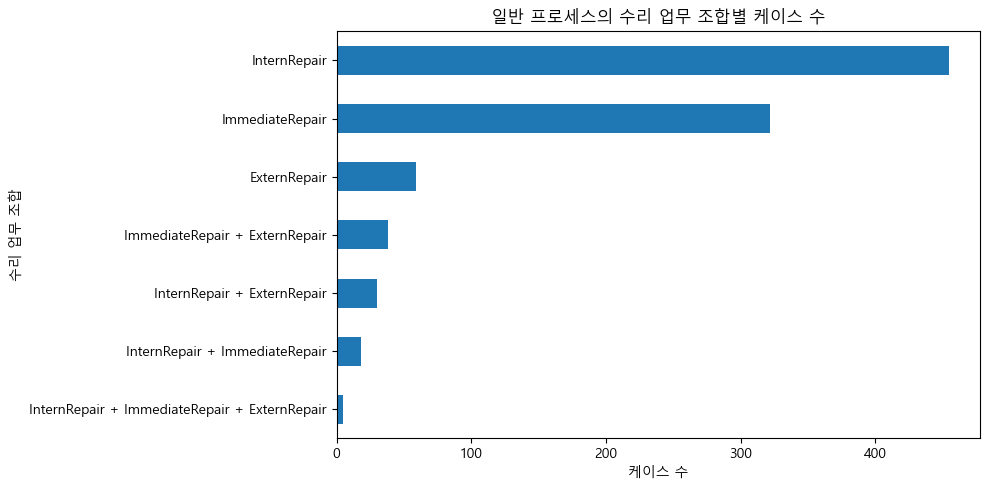

In [50]:
# 수리 업무 조합별 케이스 수 시각화
ax = combination_summary.plot.barh(
    x='수리 업무 조합',
    y='케이스 수',
    figsize=(10, 5),
    legend=False
)

ax.invert_yaxis()
ax.set_title('일반 프로세스의 수리 업무 조합별 케이스 수')
ax.set_xlabel('케이스 수')
ax.set_ylabel('수리 업무 조합')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 일반 프로세스 안에서도 수리 업무가 단독으로 나타나는 경로와 여러 수리 업무가 결합된 경로가 존재
- 수리 업무가 하나만 기록된 케이스는 836건(90.2%)이고 두 가지 이상 기록된 케이스는 91건(9.8%)
- 수리 업무가 여러 가지 존재한다는 사실과 실제로 어느 단계에서 분기한다는 것은 다르다.

##### 10-4-2. 실제 업무 순서를 바탕으로 주요 분기 지점 확인

- Survey 완료 이후 어떤 수리 업무가 시작되며 최초 수리 업무는 어떻게 구분될까?

① 첫 번째 수리 업무 확인

In [51]:
# 시간 분석 후보 중 일반 프로세스 선택
general_ids = case_paths[
    case_paths == '일반 프로세스'
].index

flow = time_cases[
    time_cases['caseID'].isin(general_ids)
].copy()

# 수리 업무의 시작 이벤트 추출
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

repair_starts = flow[
    flow['taskID'].isin(repair_tasks) &
    flow['eventtype'].eq('start')
]

# 케이스별 가장 이른 수리 시작 시각
first_time = repair_starts.groupby('caseID')['timestamp'].min().rename('첫_수리_시각')

# 최초 시각에 시작된 수리 업무 추출
first_rows = repair_starts.join(first_time, on='caseID')
first_rows = first_rows[
    first_rows['timestamp'] == first_rows['첫_수리_시각']
]

# 첫 수리 업무별 케이스 수
first_repair = first_rows.groupby('caseID')['taskID'].agg(
    lambda x: ' + '.join(sorted(x.unique()))
)

first_summary = first_repair.value_counts().to_frame('케이스 수')
first_summary['비율(%)'] = (
    first_summary['케이스 수'] / len(first_repair) * 100
).round(1)

display(first_summary)

,케이스 수,비율(%)
taskID,,
InternRepair,183,54.0
ImmediateRepair,132,38.9
ExternRepair,24,7.1


② Survey 완료와 첫 수리 시작 시점 비교

In [61]:
# 케이스별 Survey 완료 시각
survey_end = (
    flow[
        (flow['taskID'] == 'Survey') &
        (flow['eventtype'] == 'complete')
    ]
    .groupby('caseID')['timestamp']
    .min()
    .rename('Survey 완료')
)

# Survey 완료와 첫 수리 시작 시각 비교
time_check = pd.concat([survey_end, first_time], axis=1)

time_check['차이(분)'] = (
    time_check['첫_수리_시각'] - time_check['Survey 완료']
).dt.total_seconds() / 60

# 시각 관계 분류
time_check['시간 관계'] = '시각 확인 불가'
time_check.loc[time_check['차이(분)'] == 0, '시간 관계'] = '즉시 시작'
time_check.loc[time_check['차이(분)'] > 0, '시간 관계'] = ' 완료 후 수리 시작'
time_check.loc[time_check['차이(분)'] < 0, '시간 관계'] = '수리 시작이 더 빠름'

display(time_check['시간 관계'].value_counts().to_frame('케이스 수'))

,케이스 수
시간 관계,
즉시 시작,190
완료 후 수리 시작,148
시각 확인 불가,1


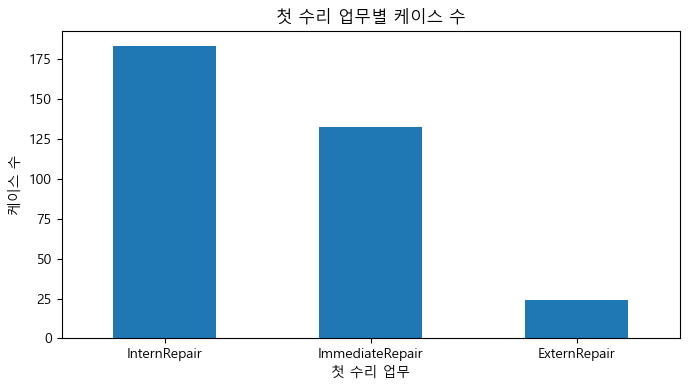

In [62]:
# 첫 수리 업무별 케이스 수
ax = first_summary['케이스 수'].plot.bar(
    figsize=(7, 4),
    rot=0
)

ax.set_title('첫 수리 업무별 케이스 수')
ax.set_xlabel('첫 수리 업무')
ax.set_ylabel('케이스 수')

plt.tight_layout()
plt.show()

**분석 결과 기록**

- 날짜 기준을 충족한 일반 프로세스 339개 케이스에서 최초 수리 업무는 InternRepair 183건(54.0%), ImmediateRepair 132건(38.9%), ExternRepair 24건(7.1%)으로 구분
- Survey 완료와 첫 수리 시작 시각을 비교한 결과 190건은 동일 시각이었으며 148건은 Survey 완료 이후 수리가 시작

-> 이러한 결과는 Survey 이후 수리 업무가 분기되는 프로세스 구조를 뒷받침

##### 10-4-3. 수리 업무 전환 패턴 분석
- 복합 수리 케이스에서는 첫 수리 이후 어떤 업무로 전환되며 업무 간 연결 관계는 일관적인가?

In [63]:
# 수리 업무 시작 이벤트 추출
start_events = flow.loc[
    flow['taskID'].isin(repair_tasks) &
    flow['eventtype'].eq('start'),
    ['caseID', 'taskID', 'timestamp']
]

# 케이스별 각 수리 업무의 최초 시작 시각
first_starts = (
    start_events.groupby(['caseID', 'taskID'], as_index=False)['timestamp']
    .min()
)

# 두 종류 이상의 수리 업무가 기록된 케이스
multi = first_starts.groupby('caseID').filter(
    lambda x: x['taskID'].nunique() >= 2
).copy()

# 동일 시각에 서로 다른 수리 업무가 시작된 케이스 확인
tie_count = (
    multi.groupby(['caseID', 'timestamp'])['taskID']
    .nunique().gt(1).sum()
)

# 첫 시작 시각을 기준으로 수리 업무 순서 정리
multi = multi.sort_values(['caseID', 'timestamp'], kind='stable')

sequences = multi.groupby('caseID')['taskID'].agg(' → '.join)

print('복합 수리 케이스:', len(sequences))
print('동일 시각으로 순서가 불명확한 경우:', tie_count)

display(sequences.value_counts().to_frame('케이스 수'))

복합 수리 케이스: 30
동일 시각으로 순서가 불명확한 경우: 0


,케이스 수
taskID,
ImmediateRepair → ExternRepair,12
InternRepair → ExternRepair,11
ImmediateRepair → InternRepair,5
ImmediateRepair → InternRepair → ExternRepair,2


- ExternRepair가 포함된 복합 경로에서는 항상 다른 수리 업무가 먼저 시작된 것으로 확인
- ImmediateRepair 이후 InternRepair로 전환된 경로도 존재
- InternRepair → ImmediateRepair처럼 반대 순서로 진행된 경로는 이번 30개 케이스에서 관찰되지 않음

① 업무 전환 시점의 정합성 확인

In [64]:
# 케이스별 다음 수리 업무 확인
transitions = multi.copy()

transitions['다음_업무'] = transitions.groupby('caseID')['taskID'].shift(-1)
transitions['다음_시작'] = transitions.groupby('caseID')['timestamp'].shift(-1)

transitions = transitions.dropna(subset=['다음_업무']).copy()

# 현재 수리 업무의 첫 완료 시각 연결
completion = (
    flow[
        flow['taskID'].isin(repair_tasks) &
        flow['eventtype'].eq('complete')
    ]
    .groupby(['caseID', 'taskID'])['timestamp']
    .min()
    .rename('현재_완료')
)

transitions = transitions.join(completion, on=['caseID', 'taskID'])

# 현재 업무 완료부터 다음 업무 시작까지의 간격
transitions['간격_분'] = (
    transitions['다음_시작'] - transitions['현재_완료']
).dt.total_seconds() / 60

# 업무 전환별 시간 관계 확인
transition_summary = transitions.groupby(
    ['taskID', '다음_업무']
)['간격_분'].agg(
    전이_건수='size',
    중앙값='median',
    최솟값='min',
    최댓값='max'
)

display(transition_summary)

전이_건수  중앙값  최솟값   최댓값
taskID          다음_업무                              
ImmediateRepair ExternRepair     12  0.0  0.0   0.0
                InternRepair      7  4.0  0.0  79.0
InternRepair    ExternRepair     13  0.0  0.0   0.0

**분석 결과 기록**

- 시간 분석 후보인 일반 프로세스 339건 중 30건(8.8%)에서 서로 다른 수리 업무가 2종류 이상 기록됨
- 주요 업무 전환은 ImmediateRepair → ExternRepair 12건, InternRepair → ExternRepair 13건, ImmediateRepair → InternRepair 7건으로 확인
- ExternRepair로 전환되는 두 유형 모두 이전 업무 완료부터 외부 수리 시작까지의 시간 간격이 0분으로 나타남
- 전체 업무 전환 32건 중 28건에서 이전 업무의 완료와 다음 업무의 시작 시각이 동일하게 기록되었으며 시간 역전은 확인되지 않았음

**주의사항**
- 외부 수리로의 시간 간격이 0분이 전체를 대변하지는 않음
- 외부 수리로의 전환이 정상적인 처리 절차인지 기존 수리의 실패로 인한 재작업인지는 확인되지 않음

#### 10-5. 프로세스 맵 작성
전체 수리 요청은 일반 프로세스와 예외 처리 경로로 어떻게 나뉘며 일반 프로세스에는 어떤 수리 업무 조합이 존재하는가?

##### 10-5-1. 전체 수리 요청의 경로 구조 시각화

In [65]:
import plotly.graph_objects as go

# 일반 프로세스의 수리 업무 조합
repair_tasks = ['InternRepair', 'ImmediateRepair', 'ExternRepair']

general = case_tasks.loc[case_paths == '일반 프로세스']

combinations = general[repair_tasks].apply(
    lambda row: ' + '.join(row.index[row]), axis=1
).value_counts()

# 단일 수리와 복합 수리 구분
single = [p for p in combinations.index if ' + ' not in p]
multi = [p for p in combinations.index if ' + ' in p]

single_n = combinations[single].sum()
multi_n = combinations[multi].sum()
exception_n = (case_paths == '예외 처리 경로').sum()

# 프로세스 노드
labels = [
    f'전체 요청<br>{len(case_paths)}건',
    f'일반 프로세스<br>{len(general)}건',
    f'예외 처리<br>{exception_n}건',
    f'단일 수리<br>{single_n}건',
    f'복합 수리<br>{multi_n}건'
] + single + multi

# 노드 간 연결 및 케이스 수
sources = [0, 0, 1, 1]
targets = [1, 2, 3, 4]
values = [len(general), exception_n, single_n, multi_n]

for i, pattern in enumerate(single):
    sources.append(3)
    targets.append(5 + i)
    values.append(int(combinations[pattern]))

for i, pattern in enumerate(multi):
    sources.append(4)
    targets.append(5 + len(single) + i)
    values.append(int(combinations[pattern]))

# Sankey Diagram
fig = go.Figure(go.Sankey(
    node=dict(
        label=labels,
        pad=22,
        thickness=18,
        color=['#64748B', '#2563EB', '#F59E0B',
               '#60A5FA', '#8B5CF6']
              + ['#93C5FD'] * len(single)
              + ['#C4B5FD'] * len(multi)
    ),
    link=dict(
        source=sources,
        target=targets,
        value=values,
        color='rgba(100,116,139,0.2)'
    )
))

fig.update_layout(
    title='수리 요청의 프로세스 유형 및 업무 조합',
    font_size=12,
    height=650,
    width=1100,
    paper_bgcolor='white',
    margin=dict(l=20, r=30, t=70, b=20)
)

fig.show()

##### 10-5-2. 실제 수리 업무의 진행 순서 시각화

In [66]:
from collections import Counter

# 10-4-3에서 확인한 수리 업무 순서
routes = sequences.str.split(' → ')

# 각 단계의 업무 전환 건수 집계
edges = Counter()

for route in routes:
    previous = '수리 업무 시작'

    for i, task in enumerate(route, 1):
        current = f'{i}차 {task}'
        edges[(previous, current)] += 1
        previous = current

    edges[(previous, '마지막 수리 업무')] += 1

# Sankey용 데이터 구성
nodes = list(dict.fromkeys(
    name for edge in edges for name in edge
))
node_index = {name: i for i, name in enumerate(nodes)}

fig = go.Figure(go.Sankey(
    node=dict(
        label=nodes,
        pad=25,
        thickness=20,
        color='#3B82F6'
    ),
    link=dict(
        source=[node_index[a] for a, b in edges],
        target=[node_index[b] for a, b in edges],
        value=list(edges.values()),
        color='rgba(59,130,246,0.25)'
    )
))

fig.update_layout(
    title=f'수리 업무의 시간순 진행 경로 ({len(routes)}개 케이스)',
    font_size=12,
    width=1100,
    height=550,
    paper_bgcolor='white'
)

fig.show()

**분석 결과 기록**

1. 수리 요청의 주요 처리 경로 확인
- 전체 1,000개 케이스는 일반 프로세스 927건(92.7%)과 예외 처리 경로 73건(7.3%)으로 구분됨.
- 일반 프로세스에서는 티켓 생성, 조사, 수리, 처리 완료와 관련된 공통 업무가 확인됨.
- 예외 처리 경로는 FirstContact와 InformClientWrongPlace로 구성되며 두 업무의 논리적 순서를 접수 후 별도 안내로 해석함.
2. 일반 프로세스의 수리 업무 분기 확인
- 일반 프로세스 927건 중 단일 수리 업무가 기록된 케이스는 836건(90.2%), 복합 수리 업무가 기록된 케이스는 91건(9.8%)임.
- 시간 분석 후보 339건에서 첫 수리 업무는 InternRepair 183건(54.0%), ImmediateRepair 132건(38.9%), ExternRepair 24건(7.1%)으로 구분됨.
- 339건 중 338건에서 Survey 완료 시각과 첫 수리 시작 시각이 같거나 수리가 이후에 시작되는 것으로 확인됨.
3. 내부 수리 업무의 반복 기록 확인
- InternRepair가 반복 기록된 케이스는 38건이며 이 중 36건이 InternRepair만 포함된 수리 업무 조합에서 발생함.
- 반복 케이스 중 수리 업무의 모든 기록이 1970년인 29건을 확인한 결과 28건에서 완료 후 다시 시작하는 형태가 관찰됨.
- 반복 기록은 특정 업무 조합에 집중되어 있으나 정상적인 복수 수행인지 재작업인지는 확인되지 않음.
4. 복합 수리 업무의 전환 패턴 확인
- 시간 분석 후보 339건 중 30건에서 서로 다른 수리 업무가 2종류 이상 기록됨.
- 주요 전환은 ImmediateRepair → ExternRepair 12건, InternRepair → ExternRepair 13건, ImmediateRepair → InternRepair 7건으로 확인됨.
- 전체 업무 전환 32건 중 28건에서 이전 업무 완료와 다음 업무 시작이 동일 시각으로 기록됨.
- 외부 수리로 전환되는 두 유형 모두 전환 간격의 중앙값이 0분으로 나타남.

----

## 11. 단계별 도달률 및 중단 후보 분석

**분석 목적:** 프로세스의 어느 단계에서 케이스가 다음 업무로 진행하지 않는지 확인한다.

**앞 단계와의 연결·다음 작업:** 10단계의 경로별로 진입 대상과 정상 종료를 구분한 뒤 도달률을 계산한다. 이후에는 진행 여부에 더해 각 구간에서 얼마나 시간이 걸리는지 확인한다.

**산출물:** 주요 경로별 퍼널 및 단계별 도달률

> **주의:** 단계별 도달률 감소가 곧 고객 이탈을 의미하지 않는다. 정상적인 업무 분기나 종료를 먼저 구분한다. 비율의 분모와 관측 범위를 함께 기록한다.


#### 11-1. 퍼널 분석 기준 정의

**확인할 내용**

- 주요 업무 순서와 단계별 진입 대상 정의
- 정상 분기와 진행 중단 구분 기준 수립

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 11-2. 단계별 도달률 분석

**확인할 내용**

- 각 업무에 도달한 케이스 수 집계
- 다음 업무로 진행한 비율 확인

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 11-3. 별도 종료 경로 분석

**확인할 내용**

- InformClientWrongPlace 등 일반 수리 경로와 다른 종료 방식 확인
- 수리 속성이 미기록된 73개 케이스와의 관계 검증

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 11-4. 프로세스 중단 후보 분석

**확인할 내용**

- 다음 단계의 기록이 없는 케이스 확인
- 정상 종료, 기록 누락, 실제 중단 가능성 구분

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


**11단계 완료 기준:** 주요 경로별 퍼널 및 단계별 도달률를 정리하고, 사용한 기준·분석 대상·해석의 한계를 기록한다.


## 12. 소요 시간 및 병목 분석

**분석 목적:** 업무 수행 시간과 업무 사이 대기 시간을 구분해 지연이 발생하는 구간을 확인한다.

**앞 단계와의 연결·다음 작업:** 10단계에서 연결한 업무와 11단계에서 구분한 경로를 바탕으로 시간을 계산한다. 지연 구간을 찾은 뒤 담당 업무 배분과 요청 특성이 관련되는지 살펴본다.

**산출물:** 처리 시간 분포 그래프 및 주요 병목 구간

> **주의:** 최초~최종 기록 간격이 실제 접수~수리 완료 시간과 같은지 확인한다. 병렬 업무의 겹침이나 음수 간격을 대기 시간으로 단정하지 않는다. 표본 수와 중앙값을 함께 제시한다.


#### 12-1. 업무별 처리 시간 계산

**확인할 내용**

- 동일 업무의 start~complete 연결
- 업무별 처리 시간 분포 확인

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 12-2. 케이스별 전체 처리 시간 분석

**확인할 내용**

- 최초 기록부터 최종 기록까지 소요 시간 계산
- 중앙값, 분포, 이상치 확인

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 12-3. 업무 간 대기 시간 분석

**확인할 내용**

- 이전 업무 완료부터 다음 업무 시작까지의 시간 확인
- 주요 대기 구간 비교

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 12-4. 병목 구간 도출

**확인할 내용**

- 처리 시간이 긴 업무 확인
- 대기 시간이 긴 업무 전이 확인
- 반복으로 전체 시간이 증가하는 구간 확인

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


**12단계 완료 기준:** 처리 시간 분포 그래프 및 주요 병목 구간를 정리하고, 사용한 기준·분석 대상·해석의 한계를 기록한다.


## 13. 담당자별 업무 분석

**분석 목적:** 업무 배분과 처리 시간에 담당자별 차이가 존재하는지 확인한다.

**앞 단계와의 연결·다음 작업:** 12단계의 지연 구간과 담당 업무 구성을 연결해 본다. 담당자 차이만으로 원인을 설명하지 않고, 다음 단계에서 수리 방식과 요청 특성도 함께 검토한다.

**산출물:** 담당자별 업무량 및 동일 업무 처리 시간 비교

> **주의:** 이벤트 수는 실제 업무 수행 횟수와 다를 수 있다. 케이스 전체 시간을 한 담당자에게 귀속하지 않으며, 배정량·업무 난이도·표본 수 차이를 고려한다.


#### 13-1. 담당자별 업무 분포

**확인할 내용**

- 담당자별 처리 이벤트 수와 케이스 수 확인
- System 등 자동 기록과 실제 담당자 구분

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 13-2. 동일 업무 내 담당자별 처리 시간 비교

**확인할 내용**

- 같은 업무를 수행한 담당자들의 처리 시간 분포 비교
- 처리 건수가 적은 담당자 주의

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 13-3. 업무 집중도 및 병목 연관성 확인

**확인할 내용**

- 일부 담당자에게 업무가 집중되는지 확인
- 업무량과 처리 시간의 관계 탐색

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


**13단계 완료 기준:** 담당자별 업무량 및 동일 업무 처리 시간 비교를 정리하고, 사용한 기준·분석 대상·해석의 한계를 기록한다.


## 14. 수리 속성과 소요 시간의 관계 분석

**분석 목적:** 요청의 특성과 수리 처리 시간이 관련되어 있는지 확인한다.

**앞 단계와의 연결·다음 작업:** 7단계에서 확인한 요청 속성에 경로와 시간 결과를 결합한다. 담당자·경로·수리 방식의 관계를 함께 정리한 뒤 근거가 충분한 문제를 개선안으로 연결한다.

**산출물:** 수리 속성별 처리 시간 비교 및 지연 관련 요인 후보

> **주의:** 속성 미기록과 케이스 내 값 충돌을 확인하고 결합 전후 케이스 수를 비교한다. 예상 시간의 의미·단위가 불명확하면 실제 시간과 직접 비교하지 않는다. 연관성을 원인으로 확정하지 않는다.


#### 14-1. 케이스 단위 분석 데이터 구성

**확인할 내용**

- 수리 속성, 주요 경로, 처리 시간을 케이스별로 결합

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 14-2. 수리 속성별 처리 시간 비교

**확인할 내용**

- RepairType별 처리 시간 비교
- RepairInternally별 처리 시간 비교
- RepairCode별 처리 시간 비교

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 14-3. 예상 수리 시간과 실제 처리 시간 비교

**확인할 내용**

- EstimatedRepairTime의 의미와 단위 확인
- 비교 가능한 실제 수리 시간과 차이 분석

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 14-4. 처리 시간 관련 요인 종합

**확인할 내용**

- 주요 요인 후보 도출
- 수리 방식·업무 경로·담당자 등과의 관계 검토

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


**14단계 완료 기준:** 수리 속성별 처리 시간 비교 및 지연 관련 요인 후보를 정리하고, 사용한 기준·분석 대상·해석의 한계를 기록한다.


## 15. 분석 결과 종합 및 개선 방안

**분석 목적:** 발견한 문제를 근거로 실행 가능한 개선 방안을 제안한다.

**앞 단계와의 연결·다음 작업:** 8~14단계에서 확인한 사실과 가설을 구분해 개선 우선순위를 정한다. 최종 제안이 정리되면 기존 PPT 구성 단계에서 메시지와 근거 자료를 연결한다.

**산출물:** 문제 → 근거 → 개선안 → 검증 지표로 연결된 최종 제안

> **주의:** 날짜 복원 불확실성과 이벤트 기록의 한계를 명시한다. 근거가 부족한 설명은 확정 결론 대신 추가 검증 과제로 남긴다.


#### 15-1. 주요 분석 결과 종합

**확인할 내용**

- 실제 프로세스 구조 정리
- 중단 및 반복 업무 정리
- 주요 병목과 처리 시간 관련 요인 정리

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 15-2. 개선 우선순위 선정

**확인할 내용**

- 문제의 발생 빈도 확인
- 지연에 미치는 영향 확인
- 개선 가능성 검토

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 15-3. 프로세스 개선 방안 제안

**확인할 내용**

- 불필요한 반복 업무 개선
- 대기 시간 단축
- 업무 배분 및 처리 절차 개선

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 15-4. 개선 효과 측정 지표 설계

**확인할 내용**

- 전체 처리 시간
- 단계별 도달률
- 재작업률
- 업무별 대기 시간

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


#### 15-5. 분석 한계 및 추가 검증 과제

**확인할 내용**

- 날짜 복원 불확실성 정리
- 이벤트 기록의 한계 정리
- 원인으로 확정할 수 없는 분석 결과 정리

**내 가설**

- 내 예상:

아래 코드 셀에서 확인하고, 실행 결과를 바탕으로 관찰 내용을 기록합니다.


**분석 결과 기록**

- 


----

## 16. 최종 PPT 구성

**A. 핵심 이야기 → B. 근거 시각화 → C. 결론과 한계**

PPT는 코드 작성 순서가 아니라 **질문에 답하는 순서**로 구성합니다.

> **기록:** **슬라이드 핵심 메시지 / 근거 자료**만 정리하고, 중요한 한계가 있으면 추가한다.


### A. 핵심 이야기


#### 16-1. PPT 목차 구성

- **확인 질문:** 처리 구조·문제·관련 요인·개선 제안을 어떤 이야기로 전달할 것인가?

- **데이터·단위:** 각 단계의 확정 결과 / 슬라이드

- **남길 결과:** 8~10장 내외의 핵심 메시지

**내 가설**

- 내 예상:


### B. 근거 시각화


#### 16-2. 표·차트 선정

- **확인 질문:** 각 결론을 뒷받침하는 최소한의 그림은 무엇인가?

- **데이터·단위:** 케이스 수·경로·시간 분포·담당자 비교 / 분석 결과

- **남길 결과:** 제목만 읽어도 메시지가 드러나는 차트

**내 가설**

- 내 예상:


**분석 결과 기록**

- 


### C. 결론과 한계


#### 16-3. 분석 한계 및 재현성

- **확인 질문:** 불확실한 날짜와 기록의 제약을 어디까지 명시해야 하는가?

- **데이터·단위:** 처리 로그·코드·검증 결과 / 보고서

- **남길 결과:** 확정 사실/가설 구분, 재현 가능한 분석 코드

**내 가설**

- 내 예상:
